In [33]:
# RNN Project - Next Day Sales Prediction
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from keras import Sequential
from keras.layers import Input,SimpleRNN,Dense


In [34]:
sales_data = {
    "Monday":100,
    "Tuesday":120,
    "Wednesday":110,
    "Thursday":140,
    "Friday":160,
    "Saturday":180,
    "Sunday":170,

    "Monday_2":190,
    "Tuesday_2":210,
    "Wednesday_2":200,
    "Thursday_2":230,
    "Friday_2":250,
    "Saturday_2":270,
    "Sunday_2":260,

    "Monday_3":270,
    "Tuesday_3":260,
    "Wednesday_3":290,
    "Thursday_3":310,
    "Friday_3":330,
    "Saturday_3":350,
    "Sunday_3":370,
}

In [35]:
df = pd.DataFrame({
    "Day":list(sales_data.keys()),
    "Sales":list(sales_data.values())
})

In [36]:
print("DAY WISE SALES DATA")
print(df.to_string(index=False))

DAY WISE SALES DATA
        Day  Sales
     Monday    100
    Tuesday    120
  Wednesday    110
   Thursday    140
     Friday    160
   Saturday    180
     Sunday    170
   Monday_2    190
  Tuesday_2    210
Wednesday_2    200
 Thursday_2    230
   Friday_2    250
 Saturday_2    270
   Sunday_2    260
   Monday_3    270
  Tuesday_3    260
Wednesday_3    290
 Thursday_3    310
   Friday_3    330
 Saturday_3    350
   Sunday_3    370


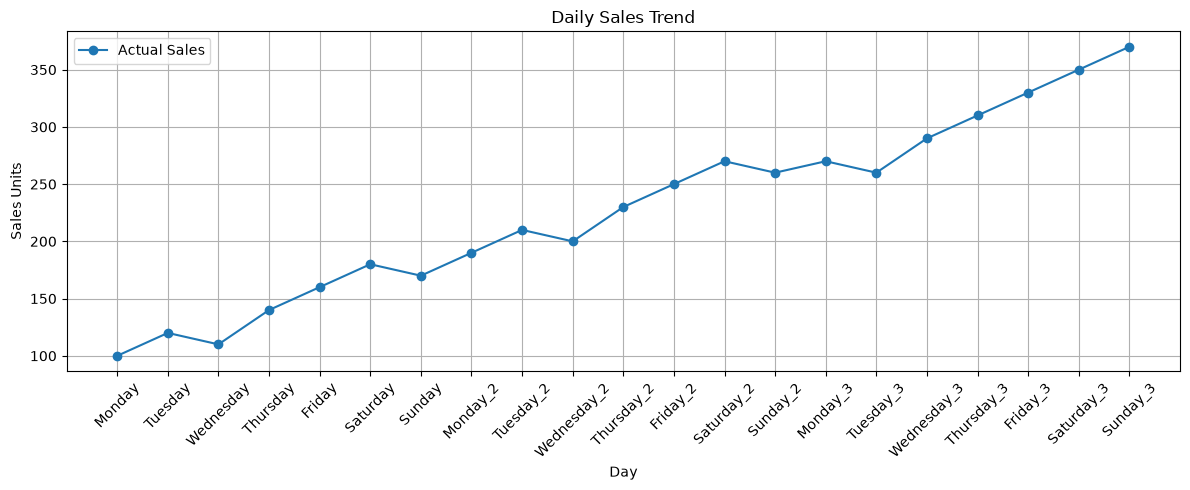

In [37]:
#data visualization
plt.figure(figsize=(12,5))
plt.plot(
    range(len(df)),
    df["Sales"],
    marker="o",
    label="Actual Sales"
)

# X axis usme label dikhane h
plt.xticks(
    range(len(df)),
    df["Day"],
    rotation=45
)

plt.title("Daily Sales Trend")
plt.xlabel("Day")
plt.ylabel("Sales Units")

plt.grid(True)
plt.legend()

# data labels vo overlap
plt.tight_layout()
plt.show()

In [38]:
# Sales value ko numpy array
sales = df["Sales"].to_numpy(dtype=np.float32)

# original sales value ko maximum scale
max_sales = float(sales.max())

# sales ko 0 to 1 me
scaled_sales = sales/max_sales


In [39]:
scaled_sales

array([0.27027026, 0.3243243 , 0.2972973 , 0.3783784 , 0.43243244,
       0.4864865 , 0.45945945, 0.5135135 , 0.5675676 , 0.5405405 ,
       0.6216216 , 0.6756757 , 0.7297297 , 0.7027027 , 0.7297297 ,
       0.7027027 , 0.7837838 , 0.8378378 , 0.8918919 , 0.9459459 ,
       1.        ], dtype=float32)

In [40]:
#input ki sequence
# pichle 3 days ki sales k hisab se agle din ki sales btani h
window_size=3
x=[]
#input seq
y=[]
# correct next day output sales

# har possible 3 days window ko input bnaye
# monday,tue,wed
for i in range(len(scaled_sales)-window_size):
    x.append(scaled_sales[i:i+window_size])

# Thursday ki sales target
    y.append(scaled_sales[i+window_size])


In [41]:
# list ko numpy array me convert krdenge
x = np.array(x,dtype=np.float32)
y = np.array(y,dtype=np.float32)

In [45]:
# RNN input shape (Samples,steps,features)
x

array([[0.27027026, 0.3243243 , 0.2972973 ],
       [0.3243243 , 0.2972973 , 0.3783784 ],
       [0.2972973 , 0.3783784 , 0.43243244],
       [0.3783784 , 0.43243244, 0.4864865 ],
       [0.43243244, 0.4864865 , 0.45945945],
       [0.4864865 , 0.45945945, 0.5135135 ],
       [0.45945945, 0.5135135 , 0.5675676 ],
       [0.5135135 , 0.5675676 , 0.5405405 ],
       [0.5675676 , 0.5405405 , 0.6216216 ],
       [0.5405405 , 0.6216216 , 0.6756757 ],
       [0.6216216 , 0.6756757 , 0.7297297 ],
       [0.6756757 , 0.7297297 , 0.7027027 ],
       [0.7297297 , 0.7027027 , 0.7297297 ],
       [0.7027027 , 0.7297297 , 0.7027027 ],
       [0.7297297 , 0.7027027 , 0.7837838 ],
       [0.7027027 , 0.7837838 , 0.8378378 ],
       [0.7837838 , 0.8378378 , 0.8918919 ],
       [0.8378378 , 0.8918919 , 0.9459459 ]], dtype=float32)

In [43]:
# RNN (Input Shape)
# (SAMPLES,Time Steps,Features)
# sample -1 total samplers automatically calculate
X = x.reshape(-1,window_size,1)

In [44]:
X

array([[[0.27027026],
        [0.3243243 ],
        [0.2972973 ]],

       [[0.3243243 ],
        [0.2972973 ],
        [0.3783784 ]],

       [[0.2972973 ],
        [0.3783784 ],
        [0.43243244]],

       [[0.3783784 ],
        [0.43243244],
        [0.4864865 ]],

       [[0.43243244],
        [0.4864865 ],
        [0.45945945]],

       [[0.4864865 ],
        [0.45945945],
        [0.5135135 ]],

       [[0.45945945],
        [0.5135135 ],
        [0.5675676 ]],

       [[0.5135135 ],
        [0.5675676 ],
        [0.5405405 ]],

       [[0.5675676 ],
        [0.5405405 ],
        [0.6216216 ]],

       [[0.5405405 ],
        [0.6216216 ],
        [0.6756757 ]],

       [[0.6216216 ],
        [0.6756757 ],
        [0.7297297 ]],

       [[0.6756757 ],
        [0.7297297 ],
        [0.7027027 ]],

       [[0.7297297 ],
        [0.7027027 ],
        [0.7297297 ]],

       [[0.7027027 ],
        [0.7297297 ],
        [0.7027027 ]],

       [[0.7297297 ],
        [0.7027027 ],
    

In [47]:
print("\nTotal Training Example : ", len(X))
print("Input Shape : ",x.shape)
print("Target Shape : ",y.shape)



Total Training Example :  18
Input Shape :  (18, 3)
Target Shape :  (18,)


In [50]:
# # TRAIN TEST SPLITTING
# 80% - Training, 20 % testing

In [51]:
split_index = int(len(X)*0.8)

In [52]:
X_train = X[:split_index]
X_test = X[split_index:]

Y_train = y[:split_index]
Y_test = y[split_index:]


In [53]:
print("Training Data example : ",len(X_train))
print("Testing Data example : ",len(X_test))


Training Data example :  14
Testing Data example :  4


In [54]:
model = Sequential(
    # Input Layer
    [Input(shape=(window_size,1)),

    # 16 Hidden units sequence patterns
    SimpleRNN(
        units=16,
        activation="tanh"
    ),

    # output
    Dense(1)

])

In [55]:
model.compile(
    optimizer="adam",
    # adam optimizer - model paramters - update
    loss = "mse"
    # mean square error
)

In [56]:
# Model Training

In [57]:
history = model.fit(X_train,Y_train,epochs=100,batch_size=4,verbose=0)
print("RNN TRAINING COMPLETED")

RNN TRAINING COMPLETED


In [58]:
# Training loss ka graph

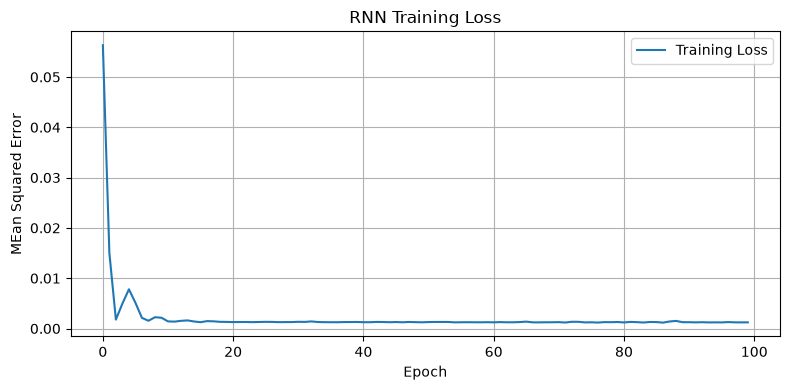

In [63]:
plt.figure(figsize=(8,4))

plt.plot(
    history.history["loss"],
    label = "Training Loss"
)

plt.title("RNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MEan Squared Error")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [64]:
# model test sequence ki prediction
predicted_scaled = model.predict(X_test,verbose=0)

In [69]:
predicted_sales = predicted_scaled.flatten()*max_sales

In [70]:
predicted_sales

array([285.8222 , 291.42957, 306.82468, 318.47086], dtype=float32)

In [73]:
actual_sales = Y_test*max_sales

In [74]:
actual_sales

array([310., 330., 350., 370.], dtype=float32)

In [81]:
# table mein actual or predicted values ko compare krenge
comparison = pd.DataFrame({
    "Actual SAles" : np.round(actual_sales,1),
        "Predicted SAles" : np.round(predicted_sales,1)
})

In [85]:
print("Actual vs Predicted Sales : ")
print(comparison.to_string(index=False))

Actual vs Predicted Sales : 
 Actual SAles  Predicted SAles
        310.0       285.799988
        330.0       291.399994
        350.0       306.799988
        370.0       318.500000


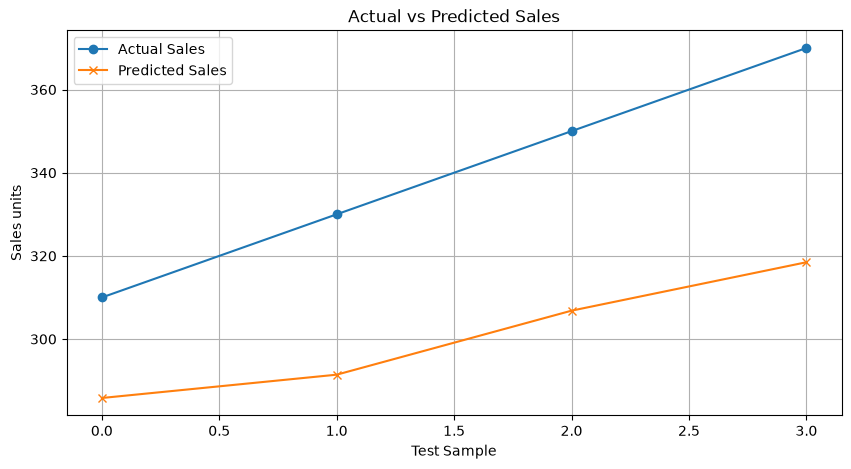

In [91]:
# Testing graph
plt.figure(figsize=(10,5))


# actual data
plt.plot(
    range(len(actual_sales)),
    actual_sales,
    marker = "o",
    label="Actual Sales"
)

# prediction data
plt.plot(
    range(len(predicted_sales)),
    predicted_sales,
    marker = "x",
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Test Sample")
plt.ylabel("Sales units")

plt.grid(True)
plt.legend()
plt.show()

In [92]:
# next day sales predict krna hai
last_three_Days = sales[-window_size:]

In [94]:
last_three_scaled = last_three_Days/max_sales

In [95]:
next_input = last_three_scaled.reshape(1,window_size,1)

In [96]:
next_prediction_scaled = model.predict(next_input,verbose=0)

In [98]:
next_prediction = next_prediction_scaled[0][0]*max_sales

In [99]:
print("Last 3 days sales : ",last_three_Days)
print("Predicted next sales : ",round(next_prediction,2))

Last 3 days sales :  [330. 350. 370.]
Predicted next sales :  329.36


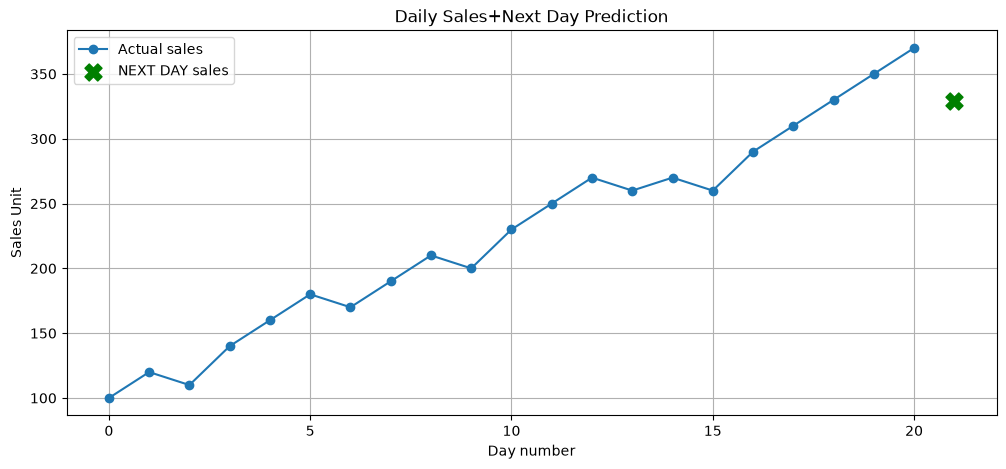

In [104]:
# data prediction graph
plt.figure(figsize=(12,5))

plt.plot(
    range(len(sales)),
    sales,
    marker="o",
    label = "Actual sales"
)

plt.scatter(
    [len(sales)],
    [next_prediction],
    marker="X",
    s=150,
    c="g",
    label= "NEXT DAY sales"
)

plt.title("Daily Sales+Next Day Prediction")
plt.xlabel("Day number")
plt.ylabel("Sales Unit")

plt.grid(True)
plt.legend()
plt.show()